In [65]:
import sys 
import os

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Move up one directory from the notebook location
notebook_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

# Add that directory to sys.path if not already present
if notebook_root not in sys.path:
    sys.path.insert(0, notebook_root)
    
from Matrix_methods.Simulate import simulate_parallel, simulate_reference
from Matrix_methods.BayesianExtractor import BayesianLayeredExtractor
from Matrix_methods.AdamExtractor import LayeredExtractor

In [66]:
# TODO:
# Smallest layers
# Cut time domain in half (test incomplete data)
# Num layer limit
# ReTest old experimental with updated code and lr 

In [67]:
import random
def generate_random_number(lims:tuple):
  """
  Generates a random number between 1.1 and 6 (inclusive) 
  and returns the number with 3 decimal places.
  """
  random_number = random.uniform(lims[0], lims[1]) 
  return round(random_number, 6)

In [68]:
[generate_random_number(lims=(20e-6, 300e-6)) for _ in range(5)]

[0.000109, 0.000252, 0.000259, 0.000234, 0.000224]

| Refractive Index | Absorption Coeff | Thickness [µm] |
|------------------|------------------|----------------|
|            3.400 |        -0.006000 |      7.000e-05 |
|            2.500 |        -0.004000 |      2.000e-04 |
|            5.400 |        -0.005000 |      1.000e-04 |
|            4.200 |        -0.001000 |      2.000e-04 |
|            1.700 |        -0.010000 |      5.000e-05 |
(Negative absorption coeff means loss in the material.)

Total Thickness: 620.0 µm


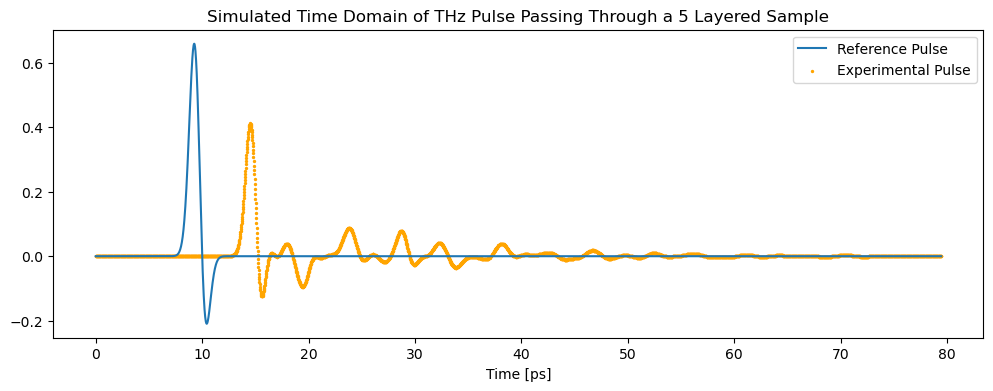

In [69]:
# Define simulation parameters
deltat = 0.0194e-12  # Time step
L = 2**12  # Number of time points

# Generate reference pulse
reference_pulse = simulate_reference(L, deltat)

n_values = [3.4, 2.5, 5.4, 4.2, 1.7]
k_values = [-0.006, -0.004, -0.005, -0.001, -0.01]
d_values = [7e-05, 0.0002, 0.0001, 0.0002, 5e-05]

# Experimental material parameters (ground truth)
material_params_exp = [[(n_values[i] + 1j * k_values[i]), d_values[i]] for i in range(len(n_values))]


# Simulate the experimental data
t_axis = np.arange(0, L * deltat, deltat)
_, experimental_pulse = simulate_parallel(reference_pulse, material_params_exp, deltat, noise_level=0)
experimental_pulse = experimental_pulse[:L]


print("| Refractive Index | Absorption Coeff | Thickness [µm] |")
print("|------------------|------------------|----------------|")

for item in material_params_exp:
    n_real = np.real(item[0])
    n_imag = np.imag(item[0])
    thickness = item[1]
    print(f"| {n_real:16.3f} | {n_imag:16.6f} | {thickness:14.3e} |")

print('(Negative absorption coeff means loss in the material.)')

print(f'\nTotal Thickness: {sum(d_values) * 1e6} µm')

plt.figure(figsize=(12,4))
plt.title(f'Simulated Time Domain of THz Pulse Passing Through a {len(n_values)} Layered Sample')
plt.plot(t_axis*1e12, reference_pulse, label='Reference Pulse')
#plt.plot(t_axis*1e12, experimental_pulse.detach().cpu().numpy(), label='Experimental Pulse')
plt.scatter(t_axis*1e12, experimental_pulse.detach().cpu().numpy(), s=2, color= 'orange',label='Experimental Pulse')
plt.xlabel('Time [ps]')
plt.legend()
plt.show()

Starting Bayesian Optimization with masks...
Search Boundaries for Optimized Parameters:
Layer 1 - n ∈ (3.314, 3.5140000000000002)
Layer 1 - k ∈ (-0.01, 0.01)
Layer 1 - D ∈ (1e-08, 0.00020999999999999998)
Layer 2 - n ∈ (2.412, 2.612)
Layer 2 - k ∈ (-0.01, 0.01)
Layer 2 - D ∈ (6.000000000000002e-05, 0.00035999999999999997)
Layer 3 - n ∈ (5.4110000000000005, 5.611)
Layer 3 - k ∈ (-0.01, 0.01)
Layer 3 - D ∈ (1e-08, 0.0003)
Layer 4 - n ∈ (4.311, 4.510999999999999)
Layer 4 - k ∈ (-0.01, 0.01)
Layer 4 - D ∈ (0.00010000000000000002, 0.00039999999999999996)
Layer 5 - n ∈ (1.66, 1.86)
Layer 5 - k ∈ (-0.01, 0.01)
Layer 5 - D ∈ (1e-08, 0.000195)
[((3.340616039940744-0.003050874779166336j), 7.71537980334233e-05), ((2.612-0.008955366802755459j), 0.00023451482884799464), ((5.477919435072429-0.004130103322638066j), 0.00010886082855000417), ((4.311+0.0066176559544436405j), 0.00012636048906629186), ((1.7685997308511128+0.01j), 0.00011666595021466301)]


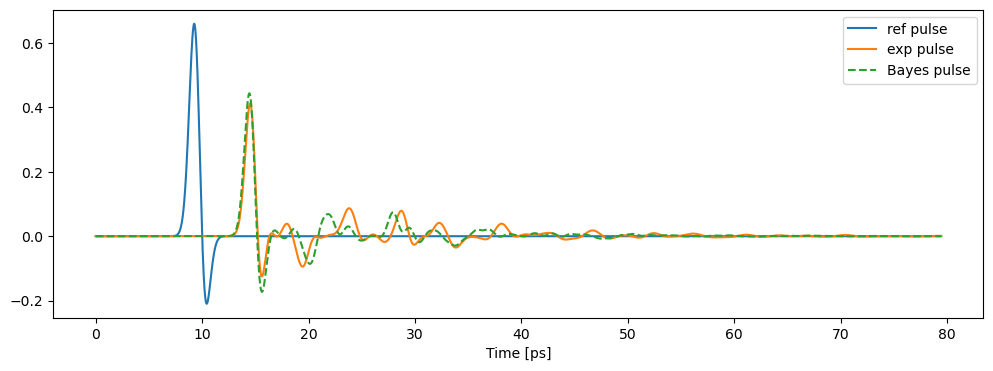

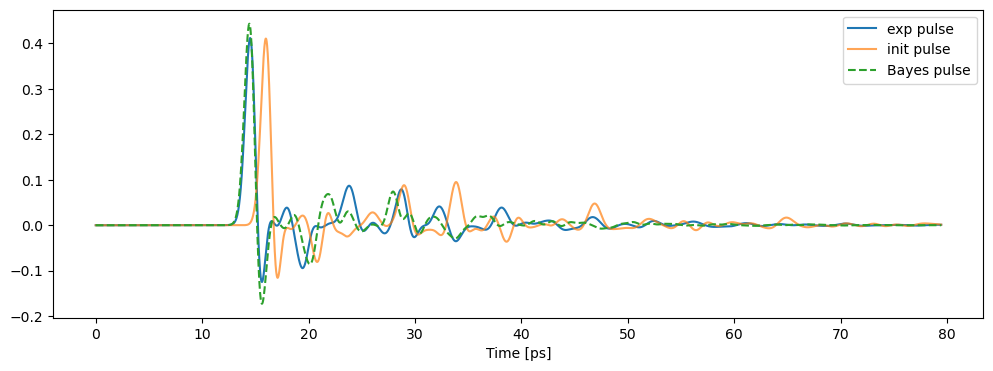

In [70]:
## Experimental params:

"""
| Refractive Index | Absorption Coeff | Thickness [µm] |
|------------------|------------------|----------------|
|            3.400 |        -0.006000 |      7.000e-05 |
|            2.500 |        -0.004000 |      2.000e-04 |
|            5.400 |        -0.005000 |      1.000e-04 |
|            4.200 |        -0.001000 |      2.000e-04 |
|            1.700 |        -0.010000 |      5.000e-05 |
(Negative absorption coeff means loss in the material.)

Total Thickness: 620.0 µm
"""

n_inits = [3.414, 2.512, 5.511, 4.411, 1.76]
k_inits = [0, 0, 0, 0, 0]
d_inits = [6e-05, 2.1e-4, 1.5e-4, 2.5e-4, 4.5e-05]


layers_init = [[(n_inits[i] + 1j * k_inits[i]), d_inits[i]] for i in range(len(n_inits))]

# Optimize with fixed thickness
optimization_mask = [
    (True, True, True),
    (True, True, True),
    (True, True, True),
    (True, True, True),
    (True, True, True)
]

initial_pulse = simulate_parallel(reference_pulse, layers_init, deltat)[1].detach().cpu().numpy()[:L]

Bayesian_optimizer = BayesianLayeredExtractor(reference_pulse, experimental_pulse, deltat, layers_init, optimize_mask=optimization_mask)
Bayesian_inits = Bayesian_optimizer.bayesian_optimization(n_calls=60)

Bayesian_pulse = simulate_parallel(reference_pulse, Bayesian_inits, deltat, noise_level=0)[1].detach().cpu().numpy()[:L]

print(Bayesian_inits)
plt.figure(figsize=(12,4))
plt.plot(t_axis*1e12, reference_pulse, label='ref pulse')
plt.plot(t_axis*1e12, experimental_pulse.detach().cpu().numpy(), label='exp pulse')
plt.plot(t_axis*1e12, Bayesian_pulse, label='Bayes pulse', linestyle='--')
plt.xlabel('Time [ps]')
plt.legend()
plt.show()

plt.figure(figsize=(12,4))
plt.plot(t_axis*1e12, experimental_pulse.detach().cpu().numpy(), label='exp pulse')
plt.plot(t_axis*1e12, initial_pulse, label='init pulse', alpha=0.7)
plt.plot(t_axis*1e12, Bayesian_pulse, label='Bayes pulse', linestyle='--')
plt.xlabel('Time [ps]')
plt.legend()
plt.show()

"""
| Refractive Index | Absorption Coeff | Thickness [µm] |
|------------------|------------------|----------------|
|            3.400 |        -0.006000 |      7.000e-05 |
|            2.500 |        -0.004000 |      2.000e-04 |
|            5.400 |        -0.005000 |      1.000e-04 |
|            4.200 |        -0.001000 |      2.000e-04 |
|            1.700 |        -0.010000 |      5.000e-05 |
(Negative absorption coeff means loss in the material.)

Total Thickness: 620.0 µm
"""

Fine-tuning 15 parameters for 50000 iterations.
Iteration 499, Loss: 3.666858e-03, Layer 0: n=3.4871, k=0.01302, D=59.87 µm | Layer 1: n=2.3969, k=-0.02978, D=231.66 µm | Layer 2: n=5.5234, k=-0.14702, D=125.27 µm | Layer 3: n=4.4137, k=0.08821, D=147.86 µm | Layer 4: n=1.4785, k=0.15635, D=81.25 µm
Iteration 999, Loss: 3.351053e-03, Layer 0: n=3.4327, k=-0.01871, D=61.52 µm | Layer 1: n=2.4023, k=-0.02943, D=231.96 µm | Layer 2: n=5.5537, k=-0.27964, D=125.43 µm | Layer 3: n=4.4292, k=0.22161, D=145.97 µm | Layer 4: n=1.4778, k=0.14943, D=78.32 µm
Iteration 1499, Loss: 3.319343e-03, Layer 0: n=3.3886, k=-0.01613, D=62.98 µm | Layer 1: n=2.3837, k=-0.02879, D=232.82 µm | Layer 2: n=5.5165, k=-0.28900, D=126.72 µm | Layer 3: n=4.4794, k=0.24051, D=143.98 µm | Layer 4: n=1.5101, k=0.13604, D=74.87 µm
Iteration 1999, Loss: 3.285821e-03, Layer 0: n=3.3568, k=-0.01202, D=63.57 µm | Layer 1: n=2.3630, k=-0.02897, D=234.61 µm | Layer 2: n=5.4966, k=-0.29466, D=127.74 µm | Layer 3: n=4.5374, k

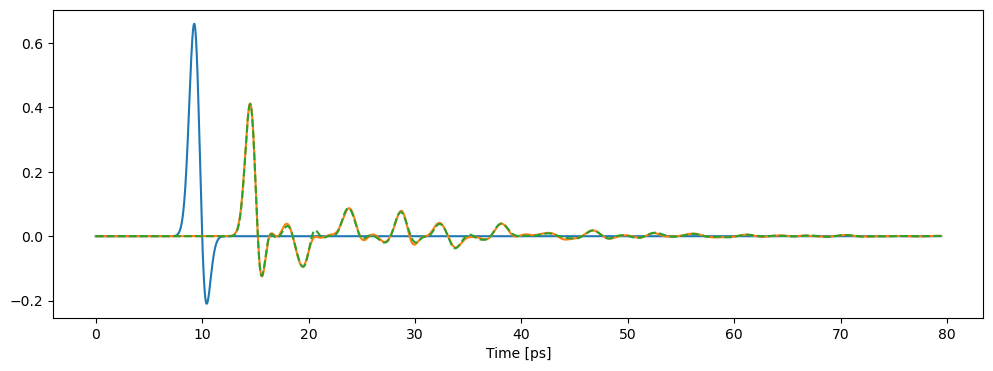

In [74]:
LE = LayeredExtractor(reference_pulse, experimental_pulse, deltat, Bayesian_inits, lr=0.001, optimize_mask=optimization_mask)
optim_params = LE.optimize(num_iterations=50000, updates=500 , alpha=1)



_, optimal_pulse = simulate_parallel(reference_pulse, optim_params, deltat, noise_level=0)
optimal_pulse = optimal_pulse[:L]

print(optim_params)
plt.figure(figsize=(12,4))
plt.plot(t_axis*1e12, reference_pulse, label='ref pulse')
plt.plot(t_axis*1e12, experimental_pulse.detach().cpu().numpy(), label='exp pulse')
plt.plot(t_axis*1e12, optimal_pulse.detach().cpu().numpy(), label='opt pulse', linestyle='--')
plt.xlabel('Time [ps]')
plt.show()

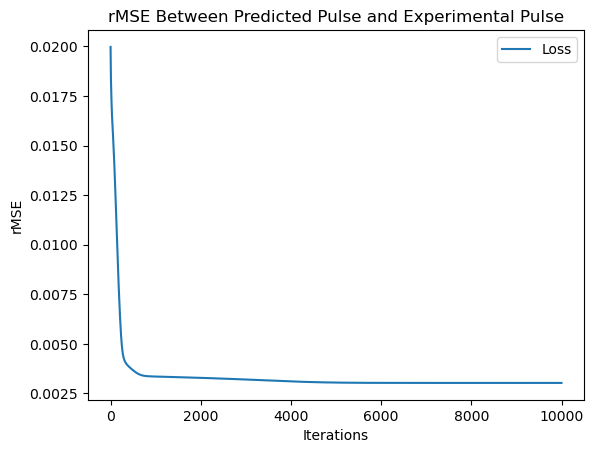

In [72]:
plt.plot(LE.loss_history, label='Loss')
plt.xlabel("Iterations")
plt.ylabel("rMSE")
plt.title("rMSE Between Predicted Pulse and Experimental Pulse")
plt.legend()
plt.show()

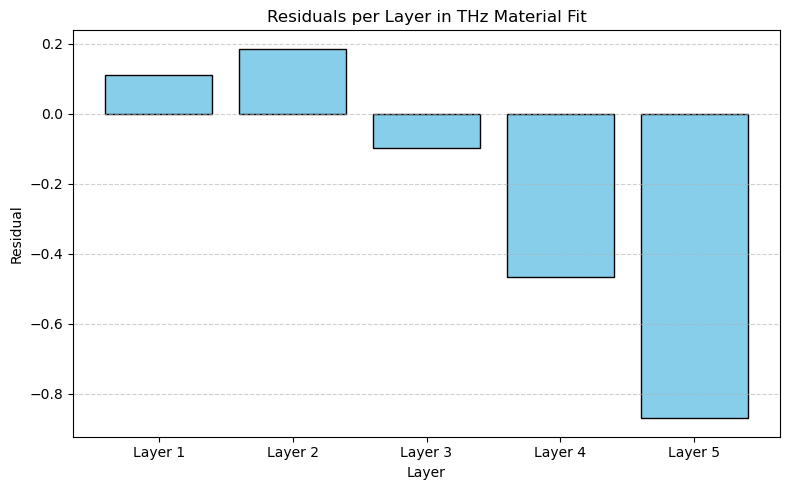

In [73]:
residuals = [material_params_exp[i][0] - optim_params[i][0] for i in range(len(material_params_exp))]
n_percentage_errors = [(np.real(residuals[i])/np.real(material_params_exp[i][0])) * 100 for i in range(len(residuals))]
k_percentage_errors = [(np.imag(residuals[i])/np.imag(material_params_exp[i][0])) * 100 for i in range(len(residuals))]

# Create bar plot
plt.figure(figsize=(8, 5))
layer_indices = [f"Layer {i+1}" for i in range(len(residuals))]

plt.bar(layer_indices, np.real(residuals), color='skyblue', edgecolor='black')
plt.title("Residuals per Layer in THz Material Fit")
plt.xlabel("Layer")
plt.ylabel("Residual")
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()